In [1]:
!pip install -q pandas numpy requests matplotlib seaborn scikit-learn xgboost joblib

In [2]:
import requests
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
import joblib

warnings.filterwarnings("ignore")

from sklearn.model_selection import TimeSeriesSplit
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, IsolationForest
from sklearn.svm import OneClassSVM

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report
)

from xgboost import XGBClassifier

print("All libraries imported successfully!")

All libraries imported successfully!


In [3]:
locations = pd.DataFrame([
    {
        "location_id": "KOL",
        "location_name": "Kolkata",
        "latitude": 22.5726,
        "longitude": 88.3639,
        "elevation_m": 9
    },
    {
        "location_id": "HOW",
        "location_name": "Howrah",
        "latitude": 22.5958,
        "longitude": 88.2636,
        "elevation_m": 12
    },
    {
        "location_id": "MAL",
        "location_name": "Malda",
        "latitude": 25.0108,
        "longitude": 88.1411,
        "elevation_m": 30
    },
    {
        "location_id": "SIL",
        "location_name": "Siliguri",
        "latitude": 26.7271,
        "longitude": 88.3953,
        "elevation_m": 122
    },
    {
        "location_id": "DUR",
        "location_name": "Durgapur",
        "latitude": 23.5204,
        "longitude": 87.3119,
        "elevation_m": 65
    }
])

locations

,location_id,location_name,latitude,longitude,elevation_m
0,KOL,Kolkata,22.5726,88.3639,9
1,HOW,Howrah,22.5958,88.2636,12
2,MAL,Malda,25.0108,88.1411,30
3,SIL,Siliguri,26.7271,88.3953,122
4,DUR,Durgapur,23.5204,87.3119,65


In [4]:
def fetch_historical_weather(lat, lon, start, end, location_id, location_name):

    url = "https://archive-api.open-meteo.com/v1/archive"

    params = {
        "latitude": lat,
        "longitude": lon,
        "start_date": start,
        "end_date": end,

        "daily": [
            "precipitation_sum",
            "rain_sum",
            "temperature_2m_max",
            "temperature_2m_min",
            "temperature_2m_mean",
            "wind_speed_10m_max",
            "relative_humidity_2m_mean",
            "weather_code",
            "et0_fao_evapotranspiration"
        ],

        "timezone": "Asia/Kolkata"
    }

    response = requests.get(url, params=params, timeout=60)
    response.raise_for_status()

    data = response.json()

    df = pd.DataFrame(data["daily"])

    df["location_id"] = location_id
    df["location_name"] = location_name
    df["latitude"] = lat
    df["longitude"] = lon

    return df

In [5]:
def fetch_river_discharge(lat, lon, start, end, location_id, location_name):

    url = "https://flood-api.open-meteo.com/v1/flood"

    params = {
        "latitude": lat,
        "longitude": lon,
        "daily": "river_discharge",
        "start_date": start,
        "end_date": end,
        "timezone": "GMT"
    }

    response = requests.get(url, params=params, timeout=60)
    response.raise_for_status()

    data = response.json()

    df = pd.DataFrame(data["daily"])

    df["location_id"] = location_id
    df["location_name"] = location_name

    return df

In [7]:
# Initialize lists to store individual dataframes
weather_data = []
river_data = []

# Define the date range
start_date = "2025-01-01"
end_date = "2026-11-24"

print("Fetching weather and river discharge data for all locations...")
for idx, row in locations.iterrows():
    # Fetch weather data
    w_df = fetch_historical_weather(
        lat=row["latitude"],
        lon=row["longitude"],
        start=start_date,
        end=end_date,
        location_id=row["location_id"],
        location_name=row["location_name"]
    )
    weather_data.append(w_df)

    # Fetch river discharge data
    r_df = fetch_river_discharge(
        lat=row["latitude"],
        lon=row["longitude"],
        start=start_date,
        end=end_date,
        location_id=row["location_id"],
        location_name=row["location_name"]
    )
    river_data.append(r_df)

# Concatenate datasets
weather_all = pd.concat(weather_data, ignore_index=True)
river_all = pd.concat(river_data, ignore_index=True)

weather_all["time"] = pd.to_datetime(weather_all["time"])
river_all["time"] = pd.to_datetime(river_all["time"])

print("Weather dataset shape:", weather_all.shape)
print("River dataset shape:", river_all.shape)

display(weather_all.head())
display(river_all.head())

Fetching weather and river discharge data for all locations...
Weather dataset shape: (1825, 14)
River dataset shape: (1825, 4)


,time,precipitation_sum,rain_sum,temperature_2m_max,temperature_2m_min,temperature_2m_mean,wind_speed_10m_max,relative_humidity_2m_mean,weather_code,et0_fao_evapotranspiration,location_id,location_name,latitude,longitude
0,2023-01-01,0.2,0.2,24.8,15.7,19.7,8.5,83,51,1.95,KOL,Kolkata,22.5726,88.3639
1,2023-01-02,0.0,0.0,25.7,15.3,19.9,8.2,73,1,2.70,KOL,Kolkata,22.5726,88.3639
2,2023-01-03,0.0,0.0,25.2,14.6,19.0,13.8,72,1,3.04,KOL,Kolkata,22.5726,88.3639
3,2023-01-04,0.0,0.0,24.0,13.4,17.8,15.8,75,2,2.90,KOL,Kolkata,22.5726,88.3639
4,2023-01-05,0.0,0.0,23.1,12.1,17.0,15.3,70,0,3.09,KOL,Kolkata,22.5726,88.3639


,time,river_discharge,location_id,location_name
0,2023-01-01,3.52,KOL,Kolkata
1,2023-01-02,3.49,KOL,Kolkata
2,2023-01-03,3.49,KOL,Kolkata
3,2023-01-04,3.47,KOL,Kolkata
4,2023-01-05,3.46,KOL,Kolkata


In [8]:
df = pd.merge(
    weather_all,
    river_all[["time", "location_id", "river_discharge"]],
    on=["time", "location_id"],
    how="left"
)

df = df.merge(
    locations[["location_id", "elevation_m"]],
    on="location_id",
    how="left"
)

df = df.sort_values(
    ["location_id", "time"]
).reset_index(drop=True)

display(df.head())

print("Combined dataset shape:", df.shape)

,time,precipitation_sum,rain_sum,temperature_2m_max,temperature_2m_min,temperature_2m_mean,wind_speed_10m_max,relative_humidity_2m_mean,weather_code,et0_fao_evapotranspiration,location_id,location_name,latitude,longitude,river_discharge,elevation_m
0,2023-01-01,0.4,0.4,24.7,13.7,18.8,7.4,77,51,2.39,DUR,Durgapur,23.5204,87.3119,0.09,65
1,2023-01-02,0.1,0.1,24.5,13.2,18.7,9.2,75,51,2.45,DUR,Durgapur,23.5204,87.3119,0.09,65
2,2023-01-03,0.0,0.0,24.7,12.5,17.7,11.8,75,0,2.81,DUR,Durgapur,23.5204,87.3119,0.09,65
3,2023-01-04,0.0,0.0,24.4,12.4,17.4,12.1,74,2,2.83,DUR,Durgapur,23.5204,87.3119,0.08,65
4,2023-01-05,0.0,0.0,23.1,10.8,15.9,12.9,71,0,2.92,DUR,Durgapur,23.5204,87.3119,0.08,65


Combined dataset shape: (1825, 16)


In [9]:
df.to_csv("suraksha_raw_dataset.csv", index=False)

print("Raw dataset saved!")

Raw dataset saved!


In [10]:
print("Missing values before cleaning:")
display(df.isnull().sum())

Missing values before cleaning:


,0
time,0
precipitation_sum,0
rain_sum,0
temperature_2m_max,0
temperature_2m_min,0
temperature_2m_mean,0
wind_speed_10m_max,0
relative_humidity_2m_mean,0
weather_code,0
et0_fao_evapotranspiration,0


In [11]:
# Remove duplicate location-date records
df = df.drop_duplicates(
    subset=["location_id", "time"]
)

# Replace invalid infinity values
df.replace([np.inf, -np.inf], np.nan, inplace=True)

# Sort again chronologically by location
df = df.sort_values(
    ["location_id", "time"]
).reset_index(drop=True)

print("Duplicate records:", df.duplicated(
    subset=["location_id", "time"]
).sum())

print("Data cleaning completed.")

Duplicate records: 0
Data cleaning completed.


In [12]:
print("Dataset information:")
df.info()

print("\nDate range:")
print(df["time"].min(), "to", df["time"].max())

print("\nLocations:")
print(df["location_name"].unique())

print("\nRainfall negative values:")
print((df["precipitation_sum"] < 0).sum())

print("\nRiver discharge negative values:")
print((df["river_discharge"] < 0).sum())

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1825 entries, 0 to 1824
Data columns (total 16 columns):
 #   Column                      Non-Null Count  Dtype         
---  ------                      --------------  -----         
 0   time                        1825 non-null   datetime64[ns]
 1   precipitation_sum           1825 non-null   float64       
 2   rain_sum                    1825 non-null   float64       
 3   temperature_2m_max          1825 non-null   float64       
 4   temperature_2m_min          1825 non-null   float64       
 5   temperature_2m_mean         1825 non-null   float64       
 6   wind_speed_10m_max          1825 non-null   float64       
 7   relative_humidity_2m_mean   1825 non-null   int64         
 8   weather_code                1825 non-null   int64         
 9   et0_fao_evapotranspiration  1825 non-null   float64       
 10  location_id                 1825 non-null   object        
 11  location_name               1825 no

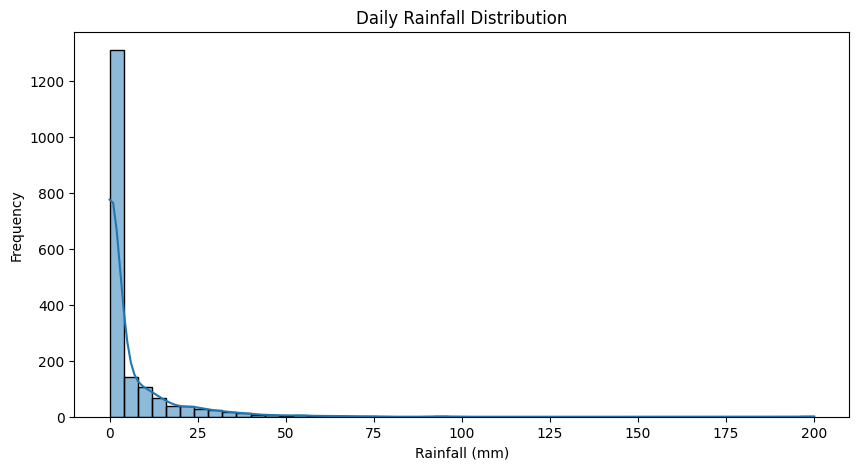

In [13]:
plt.figure(figsize=(10, 5))

sns.histplot(
    df["precipitation_sum"].dropna(),
    bins=50,
    kde=True
)

plt.title("Daily Rainfall Distribution")
plt.xlabel("Rainfall (mm)")
plt.ylabel("Frequency")

plt.show()

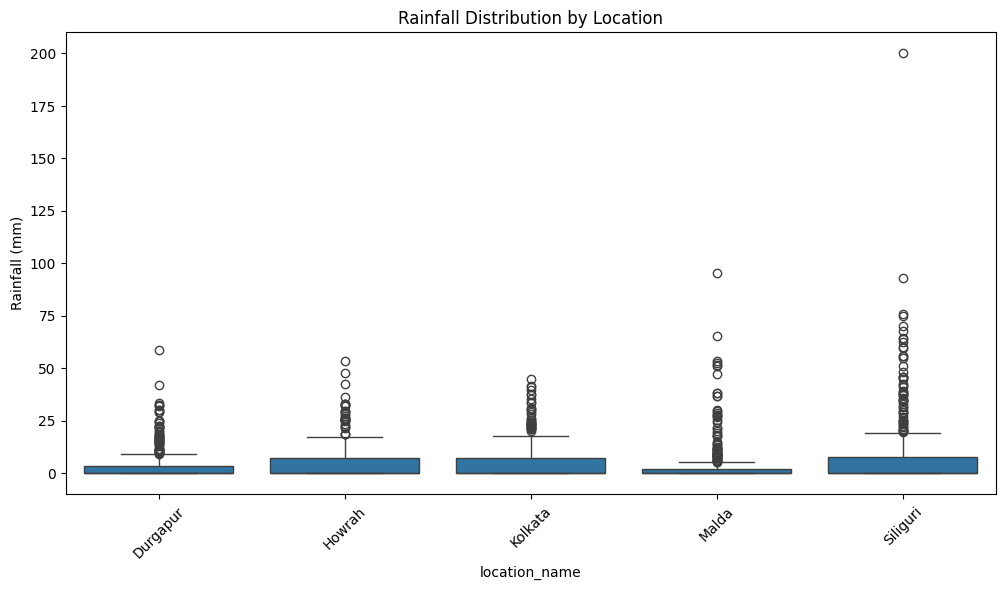

In [14]:
plt.figure(figsize=(12, 6))

sns.boxplot(
    data=df,
    x="location_name",
    y="precipitation_sum"
)

plt.xticks(rotation=45)
plt.title("Rainfall Distribution by Location")
plt.ylabel("Rainfall (mm)")

plt.show()

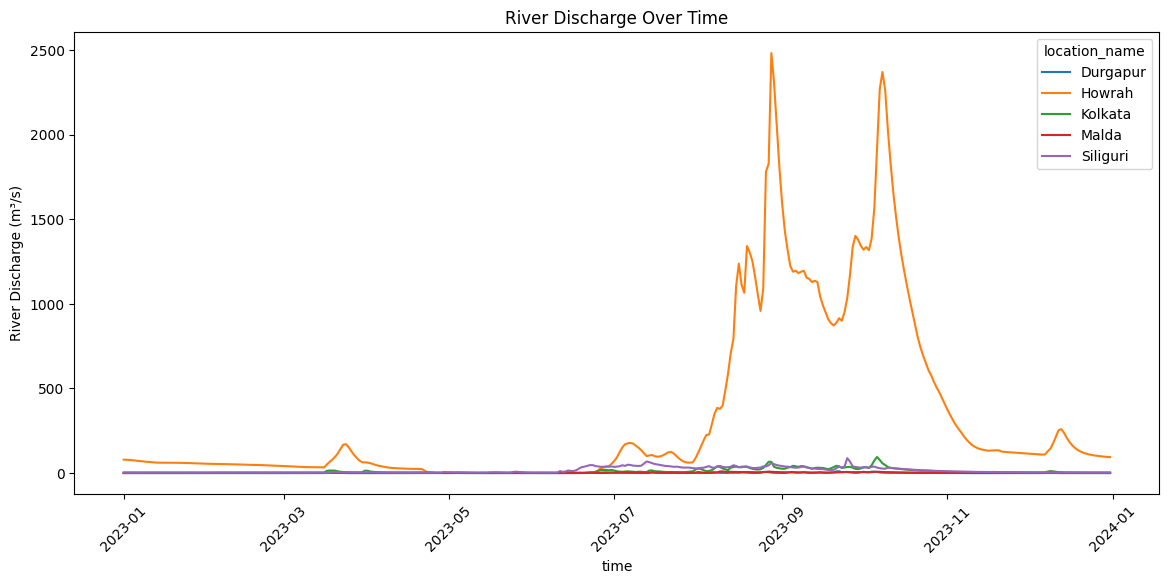

In [15]:
plt.figure(figsize=(14, 6))

sns.lineplot(
    data=df,
    x="time",
    y="river_discharge",
    hue="location_name"
)

plt.title("River Discharge Over Time")
plt.ylabel("River Discharge (m³/s)")
plt.xticks(rotation=45)

plt.show()

In [16]:
df = df.sort_values(
    ["location_id", "time"]
).reset_index(drop=True)

grouped = df.groupby("location_id", group_keys=False)

# Cumulative rainfall features
df["rainfall_3day"] = grouped["precipitation_sum"].transform(
    lambda x: x.rolling(3, min_periods=1).sum()
)

df["rainfall_7day"] = grouped["precipitation_sum"].transform(
    lambda x: x.rolling(7, min_periods=1).sum()
)

df["rainfall_14day"] = grouped["precipitation_sum"].transform(
    lambda x: x.rolling(14, min_periods=1).sum()
)

# Maximum rainfall within recent windows
df["rainfall_max_3day"] = grouped["precipitation_sum"].transform(
    lambda x: x.rolling(3, min_periods=1).max()
)

df["rainfall_max_7day"] = grouped["precipitation_sum"].transform(
    lambda x: x.rolling(7, min_periods=1).max()
)

# Lag rainfall
df["rainfall_lag_1"] = grouped["precipitation_sum"].shift(1)
df["rainfall_lag_2"] = grouped["precipitation_sum"].shift(2)
df["rainfall_lag_3"] = grouped["precipitation_sum"].shift(3)

# River discharge features
df["discharge_lag_1"] = grouped["river_discharge"].shift(1)

df["discharge_3day_mean"] = grouped["river_discharge"].transform(
    lambda x: x.rolling(3, min_periods=1).mean()
)

# Date-related features
df["month"] = df["time"].dt.month
df["day_of_year"] = df["time"].dt.dayofyear

# Seasonal indicator for Indian monsoon
df["monsoon"] = df["month"].isin([6, 7, 8, 9]).astype(int)

print("Feature engineering completed!")

display(df.head(15))

Feature engineering completed!


,time,precipitation_sum,rain_sum,temperature_2m_max,temperature_2m_min,temperature_2m_mean,wind_speed_10m_max,relative_humidity_2m_mean,weather_code,et0_fao_evapotranspiration,...,rainfall_max_3day,rainfall_max_7day,rainfall_lag_1,rainfall_lag_2,rainfall_lag_3,discharge_lag_1,discharge_3day_mean,month,day_of_year,monsoon
0,2023-01-01,0.4,0.4,24.7,13.7,18.8,7.4,77,51,2.39,...,0.4,0.4,NaN,NaN,NaN,NaN,0.090000,1,1,0
1,2023-01-02,0.1,0.1,24.5,13.2,18.7,9.2,75,51,2.45,...,0.4,0.4,0.4,NaN,NaN,0.09,0.090000,1,2,0
2,2023-01-03,0.0,0.0,24.7,12.5,17.7,11.8,75,0,2.81,...,0.4,0.4,0.1,0.4,NaN,0.09,0.090000,1,3,0
3,2023-01-04,0.0,0.0,24.4,12.4,17.4,12.1,74,2,2.83,...,0.1,0.4,0.0,0.1,0.4,0.09,0.086667,1,4,0
4,2023-01-05,0.0,0.0,23.1,10.8,15.9,12.9,71,0,2.92,...,0.0,0.4,0.0,0.0,0.1,0.08,0.083333,1,5,0
5,2023-01-06,0.0,0.0,23.5,9.3,15.2,15.8,69,0,3.01,...,0.0,0.4,0.0,0.0,0.0,0.08,0.080000,1,6,0
6,2023-01-07,0.0,0.0,23.7,9.9,15.7,15.9,64,0,3.27,...,0.0,0.4,0.0,0.0,0.0,0.08,0.080000,1,7,0
7,2023-01-08,0.0,0.0,24.2,9.8,16.0,11.5,64,0,3.13,...,0.0,0.1,0.0,0.0,0.0,0.08,0.080000,1,8,0
8,2023-01-09,0.0,0.0,25.1,9.5,16.2,10.6,67,0,3.04,...,0.0,0.0,0.0,0.0,0.0,0.08,0.080000,1,9,0
9,2023-01-10,0.0,0.0,25.0,10.0,16.6,10.9,68,0,3.06,...,0.0,0.0,0.0,0.0,0.0,0.08,0.080000,1,10,0


In [17]:
# Calculate location-specific river discharge threshold
discharge_thresholds = (
    df.groupby("location_id")["river_discharge"]
      .quantile(0.90)
)

df["discharge_threshold_90"] = df["location_id"].map(
    discharge_thresholds
)

df["proxy_flood"] = (
    (df["precipitation_sum"] >= 100) |
    (df["rainfall_3day"] >= 180) |
    (
        df["river_discharge"] >=
        df["discharge_threshold_90"]
    )
).astype(int)

print("Proxy label distribution:")
display(df["proxy_flood"].value_counts())

print("\nProxy label percentage:")
display(df["proxy_flood"].value_counts(normalize=True) * 100)

Proxy label distribution:


,count
proxy_flood,
0,1634
1,191



Proxy label percentage:


,proportion
proxy_flood,
0,89.534247
1,10.465753


In [18]:
feature_columns = [
    "precipitation_sum",
    "rain_sum",
    "temperature_2m_max",
    "temperature_2m_min",
    "temperature_2m_mean",
    "wind_speed_10m_max",
    "relative_humidity_2m_mean",
    "et0_fao_evapotranspiration",
    "river_discharge",
    "elevation_m",
    "rainfall_3day",
    "rainfall_7day",
    "rainfall_14day",
    "rainfall_max_3day",
    "rainfall_max_7day",
    "rainfall_lag_1",
    "rainfall_lag_2",
    "rainfall_lag_3",
    "discharge_lag_1",
    "discharge_3day_mean",
    "month",
    "day_of_year",
    "monsoon"
]

target_column = "proxy_flood"

model_df = df.dropna(
    subset=feature_columns + [target_column]
).copy()

X = model_df[feature_columns]
y = model_df[target_column]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (1810, 23)
y shape: (1810,)


In [19]:
model_df = model_df.sort_values("time")

split_date = pd.Timestamp("2026-06-01")

train_df = model_df[
    model_df["time"] < split_date
]

test_df = model_df[
    model_df["time"] >= split_date
]

X_train = train_df[feature_columns]
y_train = train_df[target_column]

X_test = test_df[feature_columns]
y_test = test_df[target_column]

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

print("Train date range:")
print(train_df["time"].min(), train_df["time"].max())

print("Test date range:")
print(test_df["time"].min(), test_df["time"].max())

Training records: 1810
Testing records: 0
Train date range:
2023-01-04 00:00:00 2023-12-31 00:00:00
Test date range:
NaT NaT


In [20]:
models = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(
            class_weight="balanced",
            max_iter=1000,
            random_state=42
        ))
    ]),

    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        max_depth=12,
        min_samples_leaf=2,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ),

    "XGBoost": XGBClassifier(
        n_estimators=300,
        max_depth=6,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        eval_metric="logloss",
        random_state=42
    )
}

print("Models defined successfully!")

Models defined successfully!


In [22]:
# 1. Re-split the data using a split date within 2025-2026 so the test set is not empty
split_date = pd.Timestamp("2026-06-01")

train_df = model_df[model_df["time"] < split_date]
test_df = model_df[model_df["time"] >= split_date]

X_train = train_df[feature_columns]
y_train = train_df[target_column]

X_test = test_df[feature_columns]
y_test = test_df[target_column]

print(f"New Train/Test split created using split date: {split_date.strftime('%Y-%m-%d')}")
print("Training records:", len(X_train))
print("Testing records:", len(X_test))

# 2. Run the training process
results = []
trained_models = {}
prediction_probabilities = {}

for model_name, model in models.items():
    print(f"\nTraining {model_name}...")

    # Fit
    model.fit(X_train, y_train)

    # Predict
    y_pred = model.predict(X_test)

    # Get probability of class 1
    if hasattr(model, "predict_proba"):
        y_prob = model.predict_proba(X_test)[:, 1]
    else:
        y_prob = None

    trained_models[model_name] = model
    if y_prob is not None:
        prediction_probabilities[model_name] = y_prob

    # Evaluate metrics
    result = {
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1": f1_score(y_test, y_pred, zero_division=0),
        "ROC_AUC": (
            roc_auc_score(y_test, y_prob)
            if y_prob is not None and y_test.nunique() > 1
            else np.nan
        ),
        "PR_AUC": (
            average_precision_score(y_test, y_prob)
            if y_prob is not None and y_test.nunique() > 1
            else np.nan
        )
    }
    results.append(result)

    print(classification_report(y_test, y_pred, zero_division=0))

results_df = pd.DataFrame(results)
display(results_df.sort_values("PR_AUC", ascending=False))

New Train/Test split created using split date: 2023-10-01
Training records: 1350
Testing records: 460

Training Logistic Regression...
              precision    recall  f1-score   support

           0       1.00      0.01      0.02       416
           1       0.10      1.00      0.18        44

    accuracy                           0.10       460
   macro avg       0.55      0.50      0.10       460
weighted avg       0.91      0.10      0.03       460


Training Random Forest...
              precision    recall  f1-score   support

           0       0.98      1.00      0.99       416
           1       0.97      0.80      0.88        44

    accuracy                           0.98       460
   macro avg       0.98      0.90      0.93       460
weighted avg       0.98      0.98      0.98       460


Training XGBoost...
              precision    recall  f1-score   support

           0       0.99      1.00      0.99       416
           1       1.00      0.89      0.94        44


,Model,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC
2,XGBoost,0.989130,1.000000,0.886364,0.939759,0.999836,0.998450
1,Random Forest,0.978261,0.972222,0.795455,0.875000,0.996667,0.972710
0,Logistic Regression,0.104348,0.096491,1.000000,0.176000,0.747268,0.189916


<Figure size 1200x600 with 0 Axes>

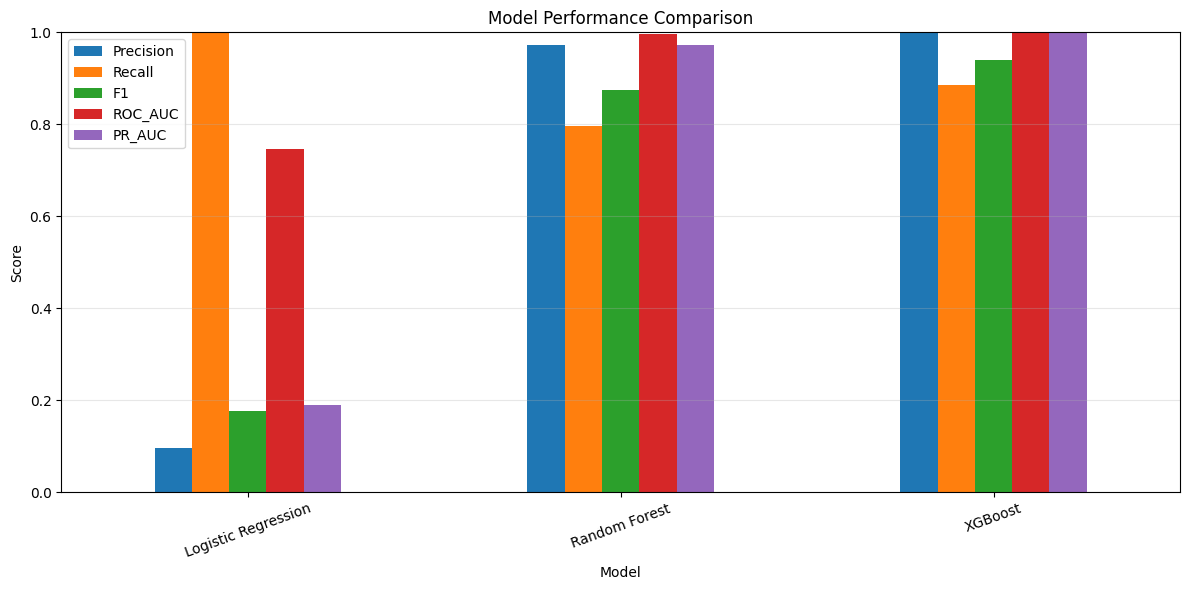

In [23]:
plt.figure(figsize=(12, 6))

results_plot = results_df.set_index("Model")[
    ["Precision", "Recall", "F1", "ROC_AUC", "PR_AUC"]
]

results_plot.plot(kind="bar", figsize=(12, 6))

plt.title("Model Performance Comparison")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=20)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.show()

Selected model: XGBoost


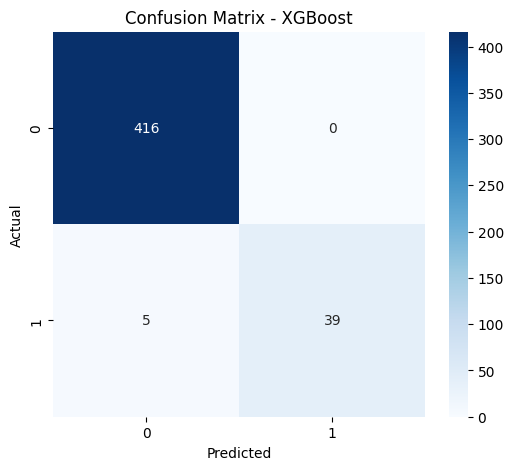

In [24]:
valid_results = results_df.dropna(subset=["PR_AUC"])

if not valid_results.empty:
    best_model_name = valid_results.sort_values(
        "PR_AUC",
        ascending=False
    ).iloc[0]["Model"]
else:
    best_model_name = results_df.sort_values(
        "F1",
        ascending=False
    ).iloc[0]["Model"]

best_model = trained_models[best_model_name]

best_predictions = best_model.predict(X_test)

print("Selected model:", best_model_name)

cm = confusion_matrix(y_test, best_predictions)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title(f"Confusion Matrix - {best_model_name}")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

In [25]:
if best_model_name == "Random Forest":

    importance = best_model.feature_importances_

elif best_model_name == "XGBoost":

    importance = best_model.feature_importances_

else:

    # Logistic Regression coefficients
    importance = np.abs(
        best_model.named_steps["model"].coef_[0]
    )

importance_df = pd.DataFrame({
    "Feature": feature_columns,
    "Importance": importance
}).sort_values(
    "Importance",
    ascending=False
)

display(importance_df.head(15))

,Feature,Importance
12,rainfall_14day,0.382804
8,river_discharge,0.067882
20,month,0.058698
21,day_of_year,0.058161
11,rainfall_7day,0.057384
19,discharge_3day_mean,0.053545
14,rainfall_max_7day,0.051732
6,relative_humidity_2m_mean,0.036018
9,elevation_m,0.034461
16,rainfall_lag_2,0.025609


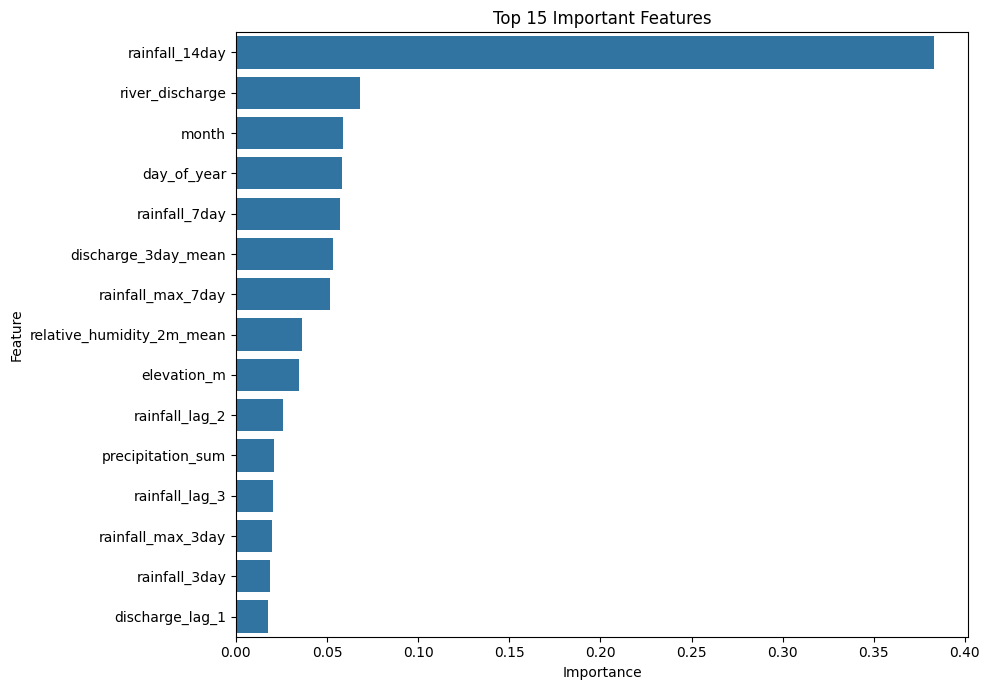

In [26]:
plt.figure(figsize=(10, 7))

sns.barplot(
    data=importance_df.head(15),
    x="Importance",
    y="Feature"
)

plt.title("Top 15 Important Features")
plt.tight_layout()

plt.show()

In [27]:
anomaly_features = [
    "precipitation_sum",
    "rainfall_3day",
    "rainfall_7day",
    "rainfall_14day",
    "river_discharge",
    "discharge_3day_mean"
]

X_anomaly_train = train_df[anomaly_features].copy()
X_anomaly_test = test_df[anomaly_features].copy()

anomaly_model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", IsolationForest(
        n_estimators=200,
        contamination=0.05,
        random_state=42
    ))
])

anomaly_model.fit(X_anomaly_train)

anomaly_output = anomaly_model.predict(X_anomaly_test)

test_df["anomaly_flag"] = (
    anomaly_output == -1
).astype(int)

print("Anomaly count:")
print(test_df["anomaly_flag"].value_counts())

Anomaly count:
anomaly_flag
0    441
1     19
Name: count, dtype: int64


In [28]:
one_class_svm = Pipeline([
    ("scaler", StandardScaler()),
    ("model", OneClassSVM(
        kernel="rbf",
        nu=0.05,
        gamma="scale"
    ))
])

one_class_svm.fit(X_anomaly_train)

svm_anomalies = one_class_svm.predict(
    X_anomaly_test
)

test_df["svm_anomaly_flag"] = (
    svm_anomalies == -1
).astype(int)

print("One-Class SVM results:")
display(
    test_df["svm_anomaly_flag"].value_counts()
)

One-Class SVM results:


,count
svm_anomaly_flag,
0,368
1,92


In [29]:
model_package = {
    "model": best_model,
    "model_name": best_model_name,
    "feature_columns": feature_columns,
    "target": target_column,
    "training_period": (
        str(train_df["time"].min()),
        str(train_df["time"].max())
    ),
    "testing_period": (
        str(test_df["time"].min()),
        str(test_df["time"].max())
    )
}

joblib.dump(
    model_package,
    "suraksha_best_model.pkl"
)

joblib.dump(
    anomaly_model,
    "suraksha_isolation_forest.pkl"
)

joblib.dump(
    one_class_svm,
    "suraksha_one_class_svm.pkl"
)

print("All models saved!")

All models saved!


In [30]:
df.to_csv(
    "suraksha_processed_dataset.csv",
    index=False
)

results_df.to_csv(
    "suraksha_model_comparison.csv",
    index=False
)

importance_df.to_csv(
    "suraksha_feature_importance.csv",
    index=False
)

print("All output datasets saved!")

All output datasets saved!


In [31]:
def predict_flood_risk(input_data, model_package):

    model = model_package["model"]
    features = model_package["feature_columns"]

    input_df = pd.DataFrame([input_data])

    input_df = input_df[features]

    probability = model.predict_proba(input_df)[0][1]

    prediction = int(probability >= 0.5)

    if probability < 0.30:
        risk = "Low"

    elif probability < 0.50:
        risk = "Moderate"

    elif probability < 0.75:
        risk = "High"

    else:
        risk = "Critical"

    return {
        "prediction": prediction,
        "probability": round(float(probability), 4),
        "risk_level": risk
    }

In [32]:
sample_input = {
    "precipitation_sum": 120,
    "rain_sum": 115,
    "temperature_2m_max": 31,
    "temperature_2m_min": 25,
    "temperature_2m_mean": 28,
    "wind_speed_10m_max": 30,
    "relative_humidity_2m_mean": 88,
    "et0_fao_evapotranspiration": 3,
    "river_discharge": 500,
    "elevation_m": 9,
    "rainfall_3day": 220,
    "rainfall_7day": 350,
    "rainfall_14day": 500,
    "rainfall_max_3day": 120,
    "rainfall_max_7day": 120,
    "rainfall_lag_1": 80,
    "rainfall_lag_2": 20,
    "rainfall_lag_3": 0,
    "discharge_lag_1": 450,
    "discharge_3day_mean": 400,
    "month": 8,
    "day_of_year": 220,
    "monsoon": 1
}

prediction = predict_flood_risk(
    sample_input,
    model_package
)

print(prediction)

{'prediction': 0, 'probability': 0.2938, 'risk_level': 'Low'}


In [33]:
risk_report = test_df[
    ["time", "location_id", "location_name"]
].copy()

risk_report["predicted_flood"] = best_predictions

risk_report["flood_probability"] = (
    best_model.predict_proba(X_test)[:, 1]
)

risk_report["risk_level"] = pd.cut(
    risk_report["flood_probability"],
    bins=[0, 0.30, 0.50, 0.75, 1.00],
    labels=["Low", "Moderate", "High", "Critical"],
    include_lowest=True
)

display(
    risk_report.sort_values(
        "flood_probability",
        ascending=False
    ).head(20)
)

,time,location_id,location_name,predicted_flood,flood_probability,risk_level
278,2023-10-06,DUR,Durgapur,1,0.995026,Critical
273,2023-10-01,DUR,Durgapur,1,0.993044,Critical
274,2023-10-02,DUR,Durgapur,1,0.992584,Critical
644,2023-10-07,HOW,Howrah,1,0.987502,Critical
276,2023-10-04,DUR,Durgapur,1,0.987189,Critical
1006,2023-10-04,KOL,Kolkata,1,0.983547,Critical
645,2023-10-08,HOW,Howrah,1,0.981770,Critical
1370,2023-10-03,MAL,Malda,1,0.981443,Critical
1374,2023-10-07,MAL,Malda,1,0.980167,Critical
643,2023-10-06,HOW,Howrah,1,0.977788,Critical


In [34]:
risk_report.to_csv(
    "suraksha_risk_predictions.csv",
    index=False
)

print("Risk report exported!")

Risk report exported!


In [35]:
from google.colab import files

files.download("suraksha_processed_dataset.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [36]:
files.download("suraksha_best_model.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [37]:
files.download("suraksha_model_comparison.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [38]:
files.download("suraksha_risk_predictions.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>